# Project 4: Music Popularity Prediction - Pass 10


## Problem Definition

This project will take data features collected for songs that have been on the Top 200 Weekly (Global) charts of Spotify in 2020 & 2021. The popularity of the song will be predicted using a tree-based regression model trained on these features.



The goals for the project are:

- Minimize the cross-validated ***root mean squared error ( RMSE )*** when predicting the popularity of a new song.

- Determine the importance of the features in driving the regression result.
The project will be done using tree-based regression techniques as covered in class. The hyperparameters of the trees should be carefully selected to avoid over-fitting.


There are three main challenges for this project:

1. Determining the outcome ( i.e. target ).  There is a "popularity" column.  But other columns may or may not be more appropriate indicators of popularity.

1. Choosing appropriate predictors ( i.e. features ). When building a machine learning model, we want to make sure that we consider how the model will be ultimately used. For this project, we are predicting the popularity of a new song. Therefore, we should only include the predictors we would have for a new song. It might help to imagine that the song will not be released for several weeks.

1. Data cleaning and feature engineering. Some creative cleaning and/or feature engineering may be needed to extract useful information for prediction.



Once again, be sure to go through the whole data science process and document as such in your Jupyter notebook.

The data is available AWS at https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv .



## Data Collection

### Imports

In [1]:
import duckdb
import pandas as pd
import os
from google.colab import userdata   # reads Colab Secrets
import matplotlib.pyplot as plt
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor


### Convert CSV to Parquet

In [2]:
url = "https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv"
url


'https://ddc-datascience.s3.amazonaws.com/Projects/Project.4-Spotify/Data/Spotify.csv'

In [3]:
# File name without the extension: 'Spotify'
base_file = url.split("/")[-1].split(".")[0]
base_file

'Spotify'

In [4]:
# Read the remote CSV and write it straight to a local parquet file (lesson 102's ETL step)
# No all_varchar here: DuckDB auto-detects types, so number columns stay numbers
con = duckdb.connect()
con.execute(f"""
    COPY (
        SELECT *
        FROM read_csv('{url}')
    )
    TO '{base_file}.parquet'
    (FORMAT PARQUET);
""")

! ls -l {base_file}.parquet

-rw-r--r-- 1 root root 255181 Nov 24 15:11 Spotify.parquet


In [5]:
# First 10 rows
duckdb.query(f'select * from "{base_file}.parquet" limit 10').df()

,Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,...,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,1,8,2021-07-23--2021-07-30,Beggin',"48,633,449",Måneskin,3377762,3Wrjm47oTz2sjIgck11l5e,"['indie rock italiano', 'italian pop']",...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,2,3,2021-07-23--2021-07-30,STAY (with Justin Bieber),"47,248,719",The Kid LAROI,2230022,5HCyWlXZPP0y6Gqq8TgA20,['australian hip hop'],...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,3,1,11,2021-06-25--2021-07-02,good 4 u,"40,162,559",Olivia Rodrigo,6266514,4ZtFanR9U6ndgddUvNcjcG,['pop'],...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,4,3,5,2021-07-02--2021-07-09,Bad Habits,"37,799,456",Ed Sheeran,83293380,6PQ88X9TkUIAUIZJHW2upE,"['pop', 'uk pop']",...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,5,1,2021-07-23--2021-07-30,INDUSTRY BABY (feat. Jack Harlow),"33,948,454",Lil Nas X,5473565,27NovPIUIRrOZoCHxABJwK,"['lgbtq+ hip hop', 'pop rap']",...,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb
5,6,1,18,2021-05-07--2021-05-14,MONTERO (Call Me By Your Name),"30,071,134",Lil Nas X,5473565,67BtfxlNbhBmCDR2L2l8qd,"['lgbtq+ hip hop', 'pop rap']",...,0.61,0.508,-6.682,0.152,0.297,0.384,178.818,137876,0.758,G#/Ab
6,7,3,16,2021-05-14--2021-05-21,Kiss Me More (feat. SZA),"29,356,736",Doja Cat,8640063,748mdHapucXQri7IAO8yFK,"['dance pop', 'pop']",...,0.762,0.701,-3.541,0.0286,0.235,0.123,110.968,208867,0.742,G#/Ab
7,8,2,10,2021-06-18--2021-06-25,Todo De Ti,"26,951,613",Rauw Alejandro,6080597,4fSIb4hdOQ151TILNsSEaF,"['puerto rican pop', 'trap latino']",...,0.78,0.718,-3.605,0.0506,0.31,0.0932,127.949,199604,0.342,D#/Eb
8,9,3,8,2021-06-18--2021-06-25,Yonaguni,"25,030,128",Bad Bunny,36142273,2JPLbjOn0wPCngEot2STUS,"['latin', 'reggaeton', 'trap latino']",...,0.644,0.648,-4.601,0.118,0.276,0.135,179.951,206710,0.44,C#/Db
9,10,8,10,2021-07-02--2021-07-09,I WANNA BE YOUR SLAVE,"24,551,591",Måneskin,3377762,4pt5fDVTg5GhEvEtlz9dKk,"['indie rock italiano', 'italian pop']",...,0.75,0.608,-4.008,0.0387,0.00165,0.178,132.507,173347,0.958,C#/Db


In [6]:
# Column names and types
duckdb.query(f'describe select * from "{base_file}.parquet"').df()

,column_name,column_type,null,key,default,extra
0,Index,BIGINT,YES,None,None,None
1,Highest Charting Position,BIGINT,YES,None,None,None
2,Number of Times Charted,BIGINT,YES,None,None,None
3,Week of Highest Charting,VARCHAR,YES,None,None,None
4,Song Name,VARCHAR,YES,None,None,None
5,Streams,VARCHAR,YES,None,None,None
6,Artist,VARCHAR,YES,None,None,None
7,Artist Followers,VARCHAR,YES,None,None,None
8,Song ID,VARCHAR,YES,None,None,None
9,Genre,VARCHAR,YES,None,None,None


### Push to Hugging Face

In [7]:
hf_account = os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account

'hmsealy'

In [8]:
hf_repo = os.environ["HF_REPO"] = "Data_Science-22"
hf_repo

'Data_Science-22'

In [9]:
hf_file = os.environ["HF_FILE"] = f"{base_file}.parquet"
hf_file

'Spotify.parquet'

In [10]:
# Get the token from Colab Secrets. Only shows the first 3 and last 4 characters
_ = hf_token = os.environ["HF_TOKEN"] = userdata.get('hf_token')
f"{_[:3]} ... {_[-4:]}"

'hf_ ... kJTa'

In [11]:
! hf auth login --token ${HF_TOKEN}

Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [12]:
%%capture hf_upload
%%bash

TARGET_REPO="${HF_ACCOUNT}/${HF_REPO}"
LOCAL_SOURCE="./${HF_FILE}"
REMOTE_DESTINATION="./${HF_FILE}"

hf upload \
  --type dataset \
  "${TARGET_REPO}" \
  "${LOCAL_SOURCE}" \
  "${REMOTE_DESTINATION}"

In [13]:
print(hf_upload.stdout)

✓ Uploaded
  url: https://huggingface.co/datasets/hmsealy/Data_Science-22/commit/813520c314e9258aa44f43f25a2eb8e9eb0fb672



### Load from Hugging Face

In [14]:
# Read the parquet file that Pass 7 pushed to Hugging Face
hf_url = "https://huggingface.co/datasets/hmsealy/Data_Science-22/resolve/main/Spotify.parquet"
hf_url

'https://huggingface.co/datasets/hmsealy/Data_Science-22/resolve/main/Spotify.parquet'

In [15]:
# Load into pandas for the rest of Passes
spotify_df = duckdb.sql(f'select * from "{hf_url}"').df()
spotify_df.head()

,Index,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Song Name,Streams,Artist,Artist Followers,Song ID,Genre,...,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,1,8,2021-07-23--2021-07-30,Beggin',"48,633,449",Måneskin,3377762,3Wrjm47oTz2sjIgck11l5e,"['indie rock italiano', 'italian pop']",...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,2,3,2021-07-23--2021-07-30,STAY (with Justin Bieber),"47,248,719",The Kid LAROI,2230022,5HCyWlXZPP0y6Gqq8TgA20,['australian hip hop'],...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,3,1,11,2021-06-25--2021-07-02,good 4 u,"40,162,559",Olivia Rodrigo,6266514,4ZtFanR9U6ndgddUvNcjcG,['pop'],...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,4,3,5,2021-07-02--2021-07-09,Bad Habits,"37,799,456",Ed Sheeran,83293380,6PQ88X9TkUIAUIZJHW2upE,"['pop', 'uk pop']",...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,5,1,2021-07-23--2021-07-30,INDUSTRY BABY (feat. Jack Harlow),"33,948,454",Lil Nas X,5473565,27NovPIUIRrOZoCHxABJwK,"['lgbtq+ hip hop', 'pop rap']",...,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb


## Data Cleaning

### Check Column Types

In [16]:
# describe
spotify_df.describe()

,Index,Highest Charting Position,Number of Times Charted
count,1556.000000,1556.000000,1556.000000
mean,778.500000,87.744216,10.668380
std,449.322824,58.147225,16.360546
min,1.000000,1.000000,1.000000
25%,389.750000,37.000000,1.000000
50%,778.500000,80.000000,4.000000
75%,1167.250000,137.000000,12.000000
max,1556.000000,200.000000,142.000000


In [17]:
# Data type of every column (object = text)
spotify_df.dtypes

,0
Index,int64
Highest Charting Position,int64
Number of Times Charted,int64
Week of Highest Charting,object
Song Name,object
Streams,object
Artist,object
Artist Followers,object
Song ID,object
Genre,object


### Choose Target and Features

Known before release (OK to use)
  - Danceability, Energy, Loudness, Speechiness, Acousticness, Liveness, Tempo, Duration (ms), Valence

Only known after release (don't use)
  - Streams, Highest Charting Position, Number of Times Charted, Week of Highest Charting

### Convert to Numbers and Drop Blanks

In [18]:
# Columns target + audio features (all known before release)
target_col = 'Popularity'
feature_cols = ['Danceability', 'Energy', 'Loudness', 'Speechiness',
                'Acousticness', 'Liveness', 'Tempo', 'Duration (ms)', 'Valence']

# Turn text into numbers. Anything that isn't a number (like a blank) becomes NaN (null)
for col in [target_col] + feature_cols:
    spotify_df[col] = pd.to_numeric(spotify_df[col], errors='coerce')

# How many nulls did that create?
spotify_df[[target_col] + feature_cols].isnull().sum()

,0
Popularity,11
Danceability,11
Energy,11
Loudness,11
Speechiness,11
Acousticness,11
Liveness,11
Tempo,11
Duration (ms),11
Valence,11


In [19]:
# Keep only rows where the target and every feature have a value
spotify_clean = spotify_df.dropna(subset=[target_col] + feature_cols).copy()
print(spotify_df.shape, spotify_clean.shape)   # before vs after

(1556, 23) (1545, 23)


In [20]:
# Now describe should show all 10 columns
spotify_clean[[target_col] + feature_cols].describe()

,Popularity,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence
count,1545.000000,1545.000000,1545.000000,1545.000000,1545.000000,1545.000000,1545.000000,1545.000000,1545.000000,1545.000000
mean,70.089320,0.689997,0.633495,-6.348474,0.123656,0.248695,0.181202,122.811023,197940.816828,0.514704
std,15.824034,0.142444,0.161577,2.509281,0.110383,0.250326,0.144071,29.591088,47148.930420,0.227326
min,0.000000,0.150000,0.054000,-25.166000,0.023200,0.000025,0.019700,46.718000,30133.000000,0.032000
25%,65.000000,0.599000,0.532000,-7.491000,0.045600,0.048500,0.096600,97.960000,169266.000000,0.343000
50%,73.000000,0.707000,0.642000,-5.990000,0.076500,0.161000,0.124000,122.012000,193591.000000,0.512000
75%,80.000000,0.796000,0.752000,-4.711000,0.165000,0.388000,0.217000,143.860000,218902.000000,0.691000
max,100.000000,0.980000,0.970000,1.509000,0.884000,0.994000,0.962000,205.272000,588139.000000,0.979000


## Exploratory Data Analysis

In [21]:
# Popularity summary: helps you judge whether an RMSE is "good" later
spotify_clean[target_col].describe()

,Popularity
count,1545.000000
mean,70.089320
std,15.824034
min,0.000000
25%,65.000000
50%,73.000000
75%,80.000000
max,100.000000


## Modeling Setup

### Split into Target and Features

In [22]:
# y = what we want to predict (the answer)
y_popularity = spotify_clean[target_col]

# X = the information the model uses to make its guess
X_features = spotify_clean[feature_cols]

print(X_features.shape, y_popularity.shape)   # check: same number of rows in both

(1545, 9) (1545,)


## Model Comparison

### Model 1: Decision Tree

In [23]:
# Try different depths. Too shallow = too simple. Too deep = memorizes the training data (overfitting)
depths = [2, 3, 4, 5, 6, 8, 10]
depth_scores = []     # will hold the average RMSE for each depth
n_search = 50         # number of splits to try for each depth

for d in depths:
    scores = np.zeros(n_search)    # empty array: one RMSE per split
    for i in range(n_search):
        X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
        model = DecisionTreeRegressor(max_depth=d, random_state=42)
        model.fit(X_train, y_train)          # learn from the training rows
        y_pred = model.predict(X_test)       # guess the test rows
        scores[i] = np.sqrt(mean_squared_error(y_test, y_pred))   # RMSE for this split
    depth_scores.append(scores.mean())       # average RMSE for this depth

# Put the results in a table
depth_df = pd.DataFrame({'Max depth': depths, 'RMSE': depth_scores})
print(depth_df)

# Pick the depth with the lowest RMSE
best_depth = depth_df.sort_values(by='RMSE')['Max depth'].iloc[0]
best_depth

   Max depth       RMSE
0          2  15.897984
1          3  16.296049
2          4  16.604057
3          5  17.040319
4          6  17.357267
5          8  18.436332
6         10  19.794587


np.int64(2)

In [24]:
# Model 1: Decision tree - repeated CV
n = 10                          # number of train/test splits (lower it if it's slow)
tree_results = np.zeros(n)       # empty array: one RMSE per split

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
    model_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
    model_tree.fit(X_train, y_train)
    y_pred = model_tree.predict(X_test)
    tree_results[i] = np.sqrt(mean_squared_error(y_test, y_pred))   # save this split's RMSE

print(f"Decision tree (max_depth={best_depth}) - mean RMSE: {tree_results.mean():.2f}")

Decision tree (max_depth=2) - mean RMSE: 15.27


### Model 2: Random Forest

In [25]:
# Model 2: try different depths for the forest. None = no limit
forest_depths = [2, 3, 4, 5, 6, 8, 10, None]
forest_depth_scores = []   # average RMSE for each depth
n_search = 5              # fewer splits than the tree, because a forest is slower

for d in forest_depths:
    scores = np.zeros(n_search)
    for i in range(n_search):
        X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
        model = RandomForestRegressor(max_depth=d, n_jobs=-1, random_state=42)   # n_jobs=-1: use all processors
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        scores[i] = np.sqrt(mean_squared_error(y_test, y_pred))
    forest_depth_scores.append(scores.mean())

forest_depth_df = pd.DataFrame({'Max depth': forest_depths, 'RMSE': forest_depth_scores})
print(forest_depth_df)

best = forest_depth_df.sort_values(by='RMSE')['Max depth'].iloc[0]
best_forest_depth = None if pd.isna(best) else int(best)
best_forest_depth

   Max depth       RMSE
0        2.0  15.126967
1        3.0  15.194697
2        4.0  15.242069
3        5.0  15.282585
4        6.0  15.343617
5        8.0  15.457640
6       10.0  15.553300
7        NaN  15.717806


2

In [26]:
# Model 2: Random forest - repeated CV
n = 10                          # must match the tree loop's n
forest_results = np.zeros(n)     # one RMSE per split

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
    model_forest = RandomForestRegressor(max_depth=best_forest_depth, n_jobs=-1, random_state=42)
    model_forest.fit(X_train, y_train)
    y_pred = model_forest.predict(X_test)
    forest_results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Random forest (max_depth={best_forest_depth}) - mean RMSE: {forest_results.mean():.2f}")

Random forest (max_depth=2) - mean RMSE: 15.03


### Model 3: XGBoost

In [27]:
# Model 3: try different depths for XGBoost
# XGBoost builds trees one after another; each new tree fixes the mistakes of the ones before it
xgb_depths = [1, 2, 3, 4, 6]
xgb_depth_scores = []    # average RMSE for each depth
n_search = 5            # same as the forest search

for d in xgb_depths:
    scores = np.zeros(n_search)
    for i in range(n_search):
        X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
        model = xgb.XGBRegressor(max_depth=d, objective='reg:squarederror',
                                 verbosity=0, seed=10, n_jobs=-1)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        scores[i] = np.sqrt(mean_squared_error(y_test, y_pred))
    xgb_depth_scores.append(scores.mean())

xgb_depth_df = pd.DataFrame({'Max depth': xgb_depths, 'RMSE': xgb_depth_scores})
print(xgb_depth_df)

best_xgb_depth = int(xgb_depth_df.sort_values(by='RMSE')['Max depth'].iloc[0])   # int() avoids the 2.0 problem
best_xgb_depth

   Max depth       RMSE
0          1  15.349408
1          2  16.211321
2          3  16.855868
3          4  17.105441
4          6  17.148477


1

In [28]:
# Model 3: XGBoost - repeated CV
n = 10                          # must match the tree and forest loops
xgb_results = np.zeros(n)        # one RMSE per split

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
    model_xgb = xgb.XGBRegressor(max_depth=best_xgb_depth, objective='reg:squarederror',
                                 verbosity=0, seed=10, n_jobs=-1)
    model_xgb.fit(X_train, y_train)
    y_pred = model_xgb.predict(X_test)
    xgb_results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"XGBoost (max_depth={best_xgb_depth}) - mean RMSE: {xgb_results.mean():.2f}")

XGBoost (max_depth=1) - mean RMSE: 15.26


### Results: Baseline vs. Models

In [29]:
# Baseline: a "model" that always guesses the average popularity of the training songs
baseline_results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=i)
    guess = np.full(len(y_test), y_train.mean())    # same guess for every test song
    baseline_results[i] = np.sqrt(mean_squared_error(y_test, guess))



In [30]:
print(f"Baseline (always guess the average): {baseline_results.mean():.2f}")
print(f"Model 1 - Decision tree:             {tree_results.mean():.2f}")
print(f"Model 2 - Random forest:             {forest_results.mean():.2f}")
print(f"Model 3 - XGBoost:                   {xgb_results.mean():.2f}")

Baseline (always guess the average): 15.19
Model 1 - Decision tree:             15.27
Model 2 - Random forest:             15.03
Model 3 - XGBoost:                   15.26


### RMSE Bar chart

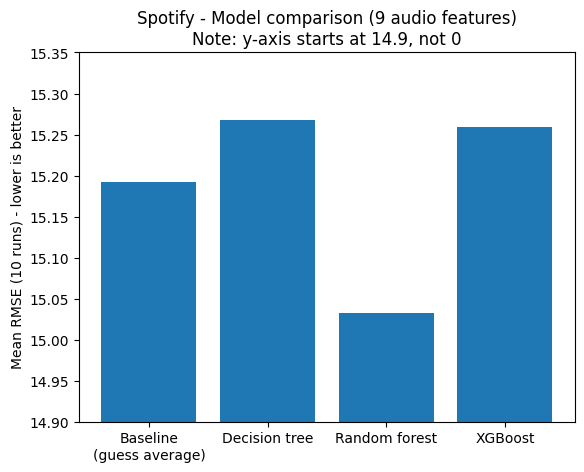

In [47]:
# Bar chart: mean RMSE of the baseline and three models (audio features, 10 runs each). Lower is better
model_names = ['Baseline\n(guess average)', 'Decision tree', 'Random forest', 'XGBoost']   # \n = new line in the label
mean_rmse = [baseline_results.mean(), tree_results.mean(),
             forest_results.mean(), xgb_results.mean()]

plt.bar(model_names, mean_rmse)

# Zoom in: start the y-axis just below the lowest score, so small differences are visible
plt.ylim(14.9, 15.35)

plt.ylabel('Mean RMSE (10 runs) - lower is better')
plt.title('Spotify - Model comparison (9 audio features)\nNote: y-axis starts at 14.9, not 0')
plt.show()

## Feature Importance

### Random Forest

In [31]:
# Fit the forest once on a fixed split to see which features it used most
X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=42)
model_forest = RandomForestRegressor(max_depth=best_forest_depth, n_jobs=-1, random_state=42)
model_forest.fit(X_train, y_train)

# Each feature's share of the error reduction (all shares add up to 1)
importance_df = pd.DataFrame({'Feature': feature_cols,
                              'Importance': model_forest.feature_importances_})
importance_df = importance_df.sort_values('Importance', ascending=False)
importance_df

,Feature,Importance
2,Loudness,0.586426
8,Valence,0.120105
5,Liveness,0.115935
7,Duration (ms),0.069394
1,Energy,0.042830
3,Speechiness,0.031926
0,Danceability,0.018077
6,Tempo,0.007931
4,Acousticness,0.007378


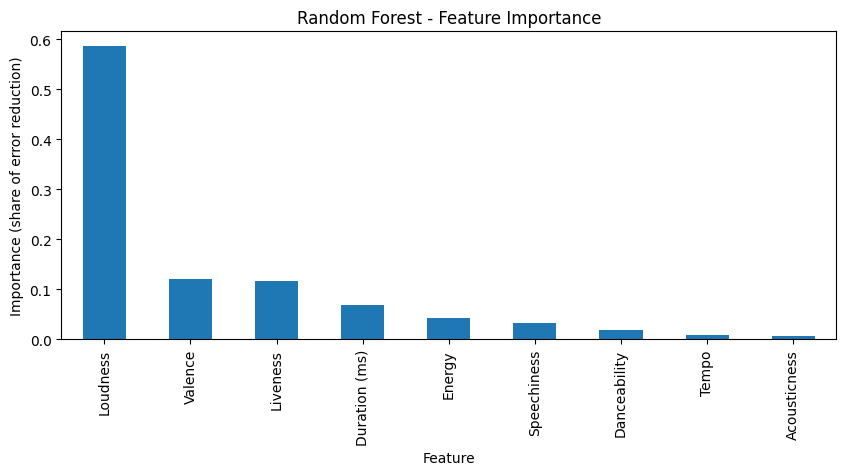

In [32]:
# Bar chart of feature importance
importance_df.plot(x='Feature', y='Importance', kind='bar', figsize=(10,4), legend=False)
plt.ylabel('Importance (share of error reduction)')
plt.title('Random Forest - Feature Importance')
plt.show()

### XGBoost

In [33]:
# Fit XGBoost once on the same fixed split as the forest
X_train, X_test, y_train, y_test = train_test_split(X_features, y_popularity, test_size=0.25, random_state=42)
model_xgb = xgb.XGBRegressor(max_depth=best_xgb_depth, objective='reg:squarederror',
                             verbosity=0, seed=10, n_jobs=-1)
model_xgb.fit(X_train, y_train)

xgb_importance_df = pd.DataFrame({'Feature': feature_cols,
                                  'Importance': model_xgb.feature_importances_})
xgb_importance_df = xgb_importance_df.sort_values('Importance', ascending=False)
xgb_importance_df

,Feature,Importance
2,Loudness,0.317872
1,Energy,0.144597
8,Valence,0.118506
7,Duration (ms),0.098925
5,Liveness,0.079466
3,Speechiness,0.074451
6,Tempo,0.063678
0,Danceability,0.059079
4,Acousticness,0.043426


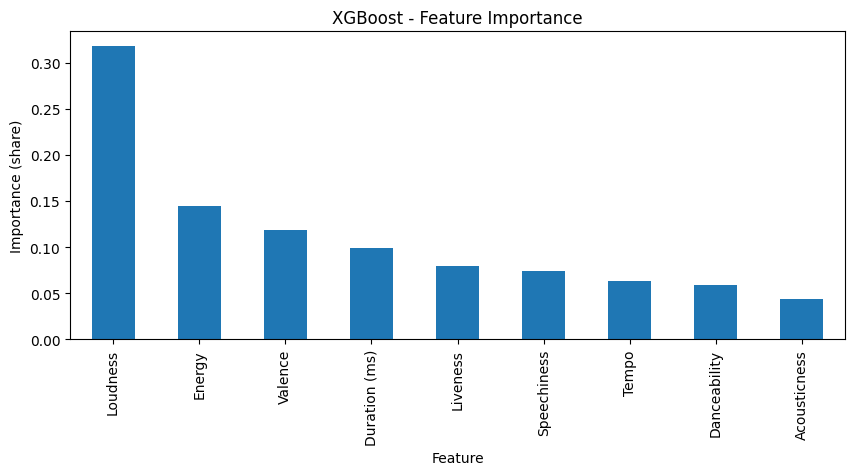

In [34]:
# Bar chart of XGBoost feature importance
xgb_importance_df.plot(x='Feature', y='Importance', kind='bar', figsize=(10,4), legend=False)
plt.ylabel('Importance (share)')
plt.title('XGBoost - Feature Importance')
plt.show()

## Pass 10: Feature Iteration
   - Pick Target, Features, and Model
   - Clean New Features
   - Iterate
   - Feature Importance (Final Model)

### Clean New Features

In [35]:
# Pass 10 uses its own copy of the data, so nothing above changes
p10_df = spotify_df.copy()

# New feature to test: Artist Followers (known before a song is released)
extra_cols = ['Artist Followers']

# Turn text into numbers. Blanks become NaN (null)
for col in extra_cols:
    p10_df[col] = pd.to_numeric(p10_df[col], errors='coerce')

# How many nulls?
p10_df[extra_cols].isnull().sum()

,0
Artist Followers,11


In [36]:
# Keep rows that have the target, all audio features, and the new features
p10_clean = p10_df.dropna(subset=[target_col] + feature_cols + extra_cols).copy()
print(p10_df.shape, p10_clean.shape)   # check: should still be about 1,545 rows

(1556, 23) (1545, 23)


### Iterate

In [37]:
# A function = a reusable recipe. Give it a list of features, get back the mean RMSE.
# It's the same random forest loop as Model 2, packaged so we can reuse it for each step.
def forest_rmse(feature_list, n=10, depth=best_forest_depth):
    X = p10_clean[feature_list]              # only the columns we asked for
    y = p10_clean[target_col]
    results = np.zeros(n)                    # one RMSE per split
    for i in range(n):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=i)
        model = RandomForestRegressor(max_depth=depth, n_jobs=-1, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        results[i] = np.sqrt(mean_squared_error(y_test, y_pred))
    return results.mean()

In [38]:
# Running table of every feature set we try
iteration_log = []

# Step 1: audio features only (should match Pass 9's forest, about 15.03)
iteration_log.append({'Step': '1. Audio only',
                      'Features': len(feature_cols),
                      'RMSE': forest_rmse(feature_cols)})

# Step 2: audio + Artist Followers
step2_cols = feature_cols + ['Artist Followers']
iteration_log.append({'Step': '2. + Artist Followers',
                      'Features': len(step2_cols),
                      'RMSE': forest_rmse(step2_cols)})

pd.DataFrame(iteration_log)

,Step,Features,RMSE
0,1. Audio only,9,15.032849
1,2. + Artist Followers,10,11.223947


In [39]:
# Depth 2 was best with weak features. Does a stronger feature let deeper trees help?
for d in [2, 3, 4, 6, 8]:
    print(d, round(forest_rmse(step2_cols, depth=d), 2))

2 11.22
3 10.72
4 10.72
6 10.74
8 10.72


In [40]:
# What does the Genre column look like? Show the 15 most common values
p10_clean['Genre'].value_counts().head(15)

,count
Genre,
[],75
"['dance pop', 'pop', 'post-teen pop']",71
"['latin', 'reggaeton', 'trap latino']",63
"['pop', 'post-teen pop']",57
"['melodic rap', 'philly rap', 'rap', 'trap']",33
"['chicago rap', 'melodic rap']",32
"['canadian pop', 'pop', 'post-teen pop']",32
['brooklyn drill'],30
"['k-pop', 'k-pop boy group']",30


In [41]:
# Broad genre groups. Each group lists words to look for, separated by | (which means "or")
genre_groups = {
    'genre_pop':    'pop',
    'genre_hiphop': 'hip hop|rap|trap',
    'genre_latin':  'latin|reggaeton|urbano|mexican',
    'genre_rock':   'rock',
    'genre_dance':  'dance|edm|house|electro',
    'genre_kpop':   'k-pop',
}

# Make lowercase text, so 'Pop' and 'pop' match the same
genre_text = p10_clean['Genre'].str.lower()

# For each group: 1 if any of its words appear in the song's genres, otherwise 0
for col_name, words in genre_groups.items():
    p10_clean[col_name] = genre_text.str.contains(words, na=False).astype(int)
    # na=False: a song with no genre gets 0 instead of an error

genre_cols = list(genre_groups.keys())

# Check: how many songs are in each group?
p10_clean[genre_cols].sum()

,0
genre_pop,819
genre_hiphop,718
genre_latin,211
genre_rock,74
genre_dance,315
genre_kpop,52


In [42]:
# Step 2 again at depth 3 (the new best depth), for a fair comparison
iteration_log.append({'Step': '2b. + Artist Followers (depth 3)',
                      'Features': len(step2_cols),
                      'RMSE': forest_rmse(step2_cols, depth=3)})

# Step 3: audio + Artist Followers + broad genres
step3_cols = step2_cols + genre_cols
iteration_log.append({'Step': '3. + Genre groups (depth 3)',
                      'Features': len(step3_cols),
                      'RMSE': forest_rmse(step3_cols, depth=3)})

pd.DataFrame(iteration_log)

,Step,Features,RMSE
0,1. Audio only,9,15.032849
1,2. + Artist Followers,10,11.223947
2,2b. + Artist Followers (depth 3),10,10.723647
3,3. + Genre groups (depth 3),16,10.716705


### Feature Importance (Final Model)
Final model: random forest, depth 3, audio features + Artist Followers (Step 2b).
Genre was dropped because it did not lower RMSE.

In [43]:
# Fit the final model once on a fixed split to see which features it relied on
X_final = p10_clean[step2_cols]
y_final = p10_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.25, random_state=42)
final_model = RandomForestRegressor(max_depth=3, n_jobs=-1, random_state=42)
final_model.fit(X_train, y_train)

# Each feature's share of the error reduction (all shares add up to 1)
final_importance_df = pd.DataFrame({'Feature': step2_cols,
                                    'Importance': final_model.feature_importances_})
final_importance_df = final_importance_df.sort_values('Importance', ascending=False)
final_importance_df

,Feature,Importance
9,Artist Followers,0.665011
2,Loudness,0.192041
7,Duration (ms),0.036465
8,Valence,0.028573
5,Liveness,0.026805
3,Speechiness,0.023708
0,Danceability,0.010987
1,Energy,0.008376
4,Acousticness,0.005136
6,Tempo,0.002897


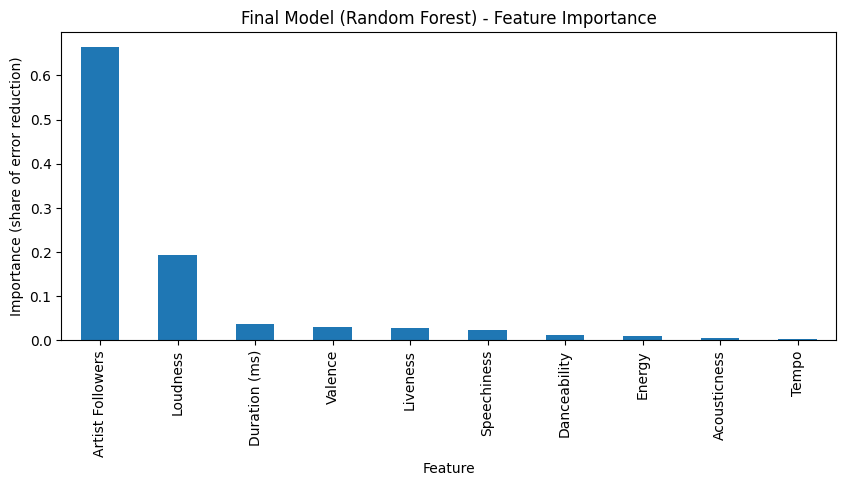

In [44]:
# Bar chart of the final model's feature importance
final_importance_df.plot(x='Feature', y='Importance', kind='bar', figsize=(10,4), legend=False)
plt.ylabel('Importance (share of error reduction)')
plt.title('Final Model (Random Forest) - Feature Importance')
plt.show()

## Pass 10: Feature Iteration
- **Target:** Popularity (same as Passes 7–9)
- **Model:** Random forest, the only model that beat the baseline in Pass 9
- **Features:** start with the 9 audio features, add new features one at a time, and keep each one only if RMSE drops

## Conclusion

**Audio features used:** Danceability, Energy, Loudness, Speechiness, Acousticness, Liveness, Tempo, Duration (ms), and Valence. These describe how a song sounds and are known before it is released.

### Model scores (audio features only, 10 splits)

| Model | Best depth | Mean RMSE |
|---|---|---|
| Baseline (always guess the average) | – | 15.19 |
| Decision tree | 2 | 15.27 |
| Random forest | 2 | **15.03** |
| XGBoost | 1 | 15.26 |

The random forest was the only model that beat the baseline, and only by 0.16 points. All three models did best with very shallow trees, which shows the audio features carry very little information about popularity. Since changing the model barely changed the score, the next step was to add new features to the random forest.

### Feature iteration (random forest)

| Step | Features | Depth | Mean RMSE |
|---|---|---|---|
| Audio only | 9 | 2 | 15.03 |
| + Artist Followers | 10 | 3 | **10.72** |
| + Genre groups | 16 | 3 | 10.72 |

**Why Artist Followers was added first:** it was the feature most likely to help, because it measures how large the artist's audience already is, while the audio features only describe the sound. It was also the easiest to add, since it is already one number per song. Adding it lowered RMSE by more than 4 points, far more than any change of model.

Genre did not lower RMSE, so it was dropped to keep the model simpler.

### Final model
Random forest, depth 3, with the 9 audio features plus Artist Followers. Mean RMSE: **10.72**. Artist Followers accounts for 67% of the feature importance, and Loudness for 19%.

